# FloraSense AI — Final Local Deep Learning Notebook
**VS Code + Jupyter + `.venv` · PyTorch + OpenCV · no frontend, no hardware**

This notebook covers:
1. Dataset inspection for all three datasets.
2. Training / validation / testing splits (70:15:15 for datasets without predefined splits; preserve predefined split folders).
3. OpenCV image loading and preprocessing.
4. Transfer learning with MobileNetV3-Large (main model) and optional ResNet18 baseline.
5. Evaluation using accuracy, macro-F1, precision, recall, confusion matrix, model size, latency and FPS.
6. Input-image inference: give a path to one leaf image and receive supported species predictions, a separate PlantVillage disease prediction, compatibility/uncertainty warnings, and available plant-care profile information.
7. Saving checkpoints and class mappings locally.

## Critical limitations
- No classifier can reliably identify literally *any* plant species. Predictions are only supported for the classes represented in its training labels. Low-confidence or out-of-distribution inputs should be reported as uncertain.
- Kaggle species labels, Campus species labels, and PlantVillage disease labels are different taxonomies. The notebook trains separate models and does not merge their class indices.
- PlantVillage disease output is only a candidate among its trained crop/disease classes. It is not a confirmed diagnosis, and it may not apply to the plant species predicted by a different model.
- Care information is returned only when a matching profile has been entered in the editable knowledge base. Do not invent a pesticide dose or treat an image-only prediction as a confirmed diagnosis.
- 95% test accuracy is a target, not something code can guarantee. Report measured held-out test metrics.

## 1. Install dependencies (run in VS Code terminal if missing)

In [27]:
# Run in VS Code PowerShell with .venv active, not in a notebook cell:
# python -m pip install torch torchvision opencv-python numpy pandas matplotlib scikit-learn pillow tqdm ipykernela

In [3]:
import os, re, json, time, copy, random, platform, warnings
from pathlib import Path
from collections import Counter

import json
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import torch
from PIL import Image
from torchvision import transforms
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torchvision
from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Python:", platform.python_version())
print("PyTorch:", torch.__version__, "| Torchvision:", torchvision.__version__)
print("OpenCV:", cv2.__version__)
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.13.1
PyTorch: 2.14.1+cpu | Torchvision: 0.29.1+cpu
OpenCV: 5.0.0
Device: cpu


## 2. Configure the three local dataset paths

The first two paths follow the paths you shared. Change them only if the folders are located elsewhere. Set `CAMPUS_DIR` to the dataset root containing `TRAIN`, `VALID`, and `TEST`, or a root containing one folder per class.

For the first two datasets, each root should directly contain the class folders. PlantVillage `raw/color` is commonly organized that way.

In [4]:
KAGGLE_DIR = Path(r"C:\Users\arnav\OneDrive\Desktop\DL Project\archive\train\train")
PLANTVILLAGE_DIR = Path(r"C:\Users\arnav\OneDrive\Desktop\DL Project\PlantVillage-Dataset-master\PlantVillage-Dataset-master\raw\color")
# This is the directory that directly contains TRAIN, VALID and TEST.
CAMPUS_DIR = Path(r"C:\Users\arnav\OneDrive\Desktop\DL Project\Campus_plants\Common_Indian_Plants")

PROJECT_DIR = Path.cwd()
MODEL_DIR = PROJECT_DIR / "models"
OUTPUT_DIR = PROJECT_DIR / "outputs"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATASET_ROOTS = {
    "kaggle_species": KAGGLE_DIR,
    "plantvillage_disease": PLANTVILLAGE_DIR,
    "campus_species": CAMPUS_DIR,
}

for name, path in DATASET_ROOTS.items():
    print(f"{name}: {path} | exists={path.exists()}")
print("Notebook working directory:", PROJECT_DIR)
print("Models will be saved to:", MODEL_DIR.resolve())
print("Outputs will be saved to:", OUTPUT_DIR.resolve())

kaggle_species: C:\Users\arnav\OneDrive\Desktop\DL Project\archive\train\train | exists=True
plantvillage_disease: C:\Users\arnav\OneDrive\Desktop\DL Project\PlantVillage-Dataset-master\PlantVillage-Dataset-master\raw\color | exists=True
campus_species: C:\Users\arnav\OneDrive\Desktop\DL Project\Campus_plants\Common_Indian_Plants | exists=True
Notebook working directory: c:\Users\arnav\OneDrive\Desktop\DL Project
Models will be saved to: C:\Users\arnav\OneDrive\Desktop\DL Project\models
Outputs will be saved to: C:\Users\arnav\OneDrive\Desktop\DL Project\outputs


## 3. Inspect folders and count images

In [6]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
SPLIT_ALIASES = {
    "train": {"train", "training"},
    "val": {"val", "valid", "validation", "dev"},
    "test": {"test", "testing"},
}

def count_images(folder):
    return sum(1 for p in Path(folder).rglob("*")
               if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)

def inspect_root(root, dataset_name):
    if root is None or not Path(root).exists():
        print(f"\n{dataset_name}: PATH NOT FOUND — edit its path in Section 2.")
        return
    root = Path(root)
    print(f"\n{dataset_name}: {root}")
    subdirs = sorted(p for p in root.iterdir() if p.is_dir() and not p.name.startswith("."))
    if not subdirs:
        print("No immediate subfolders found. Check whether this is the class-folder root.")
        return
    for d in subdirs:
        print(f"  {d.name}: {count_images(d)} images")
    print("Total images:", count_images(root))

for name, root in DATASET_ROOTS.items():
    inspect_root(root, name)


kaggle_species: C:\Users\arnav\OneDrive\Desktop\DL Project\archive\train\train
  Alstonia Scholaris: 412 images
  Arjun: 432 images
  Bael: 107 images
  Basil: 137 images
  Chinar: 203 images
  Gauva: 398 images
  Jamun: 603 images
  Jatropha: 237 images
  Lemon: 216 images
  Mango: 414 images
  Pomegranate: 538 images
  Pongamia Pinnata: 577 images
Total images: 4274

plantvillage_disease: C:\Users\arnav\OneDrive\Desktop\DL Project\PlantVillage-Dataset-master\PlantVillage-Dataset-master\raw\color
  Apple___Apple_scab: 630 images
  Apple___Black_rot: 621 images
  Apple___Cedar_apple_rust: 275 images
  Apple___healthy: 1645 images
  Blueberry___healthy: 1502 images
  Cherry_(including_sour)___healthy: 854 images
  Cherry_(including_sour)___Powdery_mildew: 1052 images
  Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 513 images
  Corn_(maize)___Common_rust_: 1192 images
  Corn_(maize)___healthy: 1162 images
  Corn_(maize)___Northern_Leaf_Blight: 985 images
  Grape___Black_rot: 1180 

## 4. Build manifests and create train/validation/test splits

- For Kaggle and PlantVillage, if the root contains class folders, this creates a reproducible stratified 70:15:15 split.
- For Campus plants, if `TRAIN`, `VALID`/`VALIDATION`, and `TEST` folders exist, their predefined split is preserved.
- If Campus has only class folders, a stratified 70:15:15 split is created.
- The split is made on original files, before any random augmentation.
- If multiple photos show the same physical leaf/plant, ideally keep those images together in one split. This notebook cannot infer plant identity without metadata.

In [7]:
def find_split_dirs(root):
    root = Path(root)
    found = {}
    for child in root.iterdir():
        if child.is_dir():
            low = child.name.lower()
            for split, aliases in SPLIT_ALIASES.items():
                if low in aliases:
                    found[split] = child
    return found if {"train", "val", "test"}.issubset(found) else None

def records_from_class_root(class_root, split_name=None):
    rows = []
    class_root = Path(class_root)
    for class_dir in sorted(p for p in class_root.iterdir()
                             if p.is_dir() and not p.name.startswith(".")):
        # If root is a split root, its immediate children should be class folders.
        for p in class_dir.rglob("*"):
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS:
                rows.append({
                    "path": str(p.resolve()),
                    "label": class_dir.name,
                    "split": split_name,
                })
    return rows

def build_manifest(root, dataset_name, use_existing_splits=False):
    root = Path(root)
    if not root.exists():
        print(f"Skipping {dataset_name}: path does not exist: {root}")
        return pd.DataFrame()

    split_dirs = find_split_dirs(root) if use_existing_splits else None
    rows = []
    if split_dirs:
        print(f"{dataset_name}: preserving existing train/validation/test folders.")
        for split, split_root in split_dirs.items():
            rows.extend(records_from_class_root(split_root, split))
    else:
        print(f"{dataset_name}: creating stratified 70:15:15 split from class folders.")
        rows.extend(records_from_class_root(root, None))

    df = pd.DataFrame(rows)
    if df.empty:
        print(f"No images found for {dataset_name}. Check root path and folder structure.")
        return df

    # Drop unreadable files using OpenCV before splitting.
    valid, bad = [], []
    for row in df.to_dict("records"):
        im = cv2.imread(row["path"], cv2.IMREAD_COLOR)
        if im is None or im.size == 0:
            bad.append(row["path"])
        else:
            valid.append(row)
    df = pd.DataFrame(valid)
    if bad:
        pd.Series(bad, name="bad_path").to_csv(
            OUTPUT_DIR / f"{dataset_name}_unreadable_images.csv", index=False
        )
        print(f"Rejected {len(bad)} unreadable images.")
    if df.empty:
        return df

    if df["split"].isna().all():
        counts = df["label"].value_counts()
        # Need at least 3 samples per class for a meaningful stratified 3-way split.
        rare = counts[counts < 3]
        if not rare.empty:
            print("Warning: classes with fewer than 3 images cannot support a reliable 3-way split:")
            display(rare.to_frame("images"))
        try:
            train_df, temp_df = train_test_split(
                df, test_size=0.30, random_state=SEED, stratify=df["label"]
            )
            val_df, test_df = train_test_split(
                temp_df, test_size=0.50, random_state=SEED, stratify=temp_df["label"]
            )
            df = pd.concat([
                train_df.assign(split="train"),
                val_df.assign(split="val"),
                test_df.assign(split="test")
            ], ignore_index=True)
        except ValueError as e:
            raise ValueError(
                f"Cannot create stratified 70:15:15 split for {dataset_name}. "
                f"Check class counts and collect/retain more images per class. Original error: {e}"
            )
    else:
        # Validate predefined split labels and label compatibility.
        df["split"] = df["split"].astype(str)

    df.to_csv(OUTPUT_DIR / f"{dataset_name}_manifest.csv", index=False)
    print(f"\n{dataset_name}: {len(df)} valid images, {df['label'].nunique()} classes")
    display(df.groupby(["split", "label"]).size().unstack(fill_value=0))
    return df

manifests = {
    "kaggle_species": build_manifest(KAGGLE_DIR, "kaggle_species"),
    "plantvillage_disease": build_manifest(PLANTVILLAGE_DIR, "plantvillage_disease"),
    "campus_species": build_manifest(CAMPUS_DIR, "campus_species", use_existing_splits=True),
}

kaggle_species: creating stratified 70:15:15 split from class folders.

kaggle_species: 4274 valid images, 12 classes


label,Alstonia Scholaris,Arjun,Bael,Basil,Chinar,Gauva,Jamun,Jatropha,Lemon,Mango,Pomegranate,Pongamia Pinnata
split,,,,,,,,,,,,
test,62,65,16,20,30,60,91,36,32,62,81,87
train,288,302,75,96,142,279,422,166,151,290,376,404
val,62,65,16,21,31,59,90,35,33,62,81,86


plantvillage_disease: creating stratified 70:15:15 split from class folders.

plantvillage_disease: 54305 valid images, 38 classes


label,Apple___Apple_scab,Apple___Black_rot,Apple___Cedar_apple_rust,Apple___healthy,Blueberry___healthy,Cherry_(including_sour)___Powdery_mildew,Cherry_(including_sour)___healthy,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,Corn_(maize)___Common_rust_,Corn_(maize)___Northern_Leaf_Blight,...,Tomato___Bacterial_spot,Tomato___Early_blight,Tomato___Late_blight,Tomato___Leaf_Mold,Tomato___Septoria_leaf_spot,Tomato___Spider_mites Two-spotted_spider_mite,Tomato___Target_Spot,Tomato___Tomato_Yellow_Leaf_Curl_Virus,Tomato___Tomato_mosaic_virus,Tomato___healthy
split,,,,,,,,,,,,,,,,,,,,,
test,94,93,41,246,226,158,128,77,179,147,...,319,150,287,143,265,252,211,803,56,239
train,441,435,193,1152,1051,736,598,359,834,690,...,1489,700,1336,666,1240,1173,983,3750,261,1114
val,95,93,41,247,225,158,128,77,179,148,...,319,150,286,143,266,251,210,804,56,238


campus_species: preserving existing train/validation/test folders.

campus_species: 14225 valid images, 10 classes


label,Aloe,Corn,Guava,Hibiscus,Lemon,Mango,Neem,Rice,Tomato,Tulsi
split,,,,,,,,,,
test,410,291,406,396,315,385,377,262,430,362
train,983,697,937,848,754,920,884,627,899,869
val,245,174,221,272,188,229,221,156,250,217


## 5. Visual audit of class labels and images

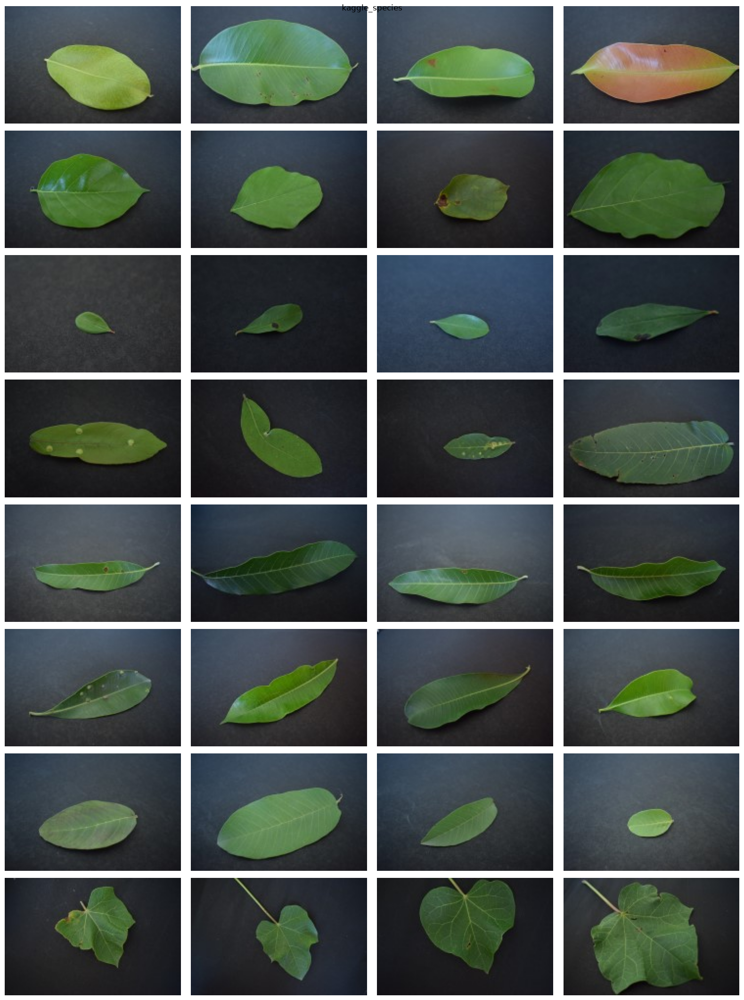

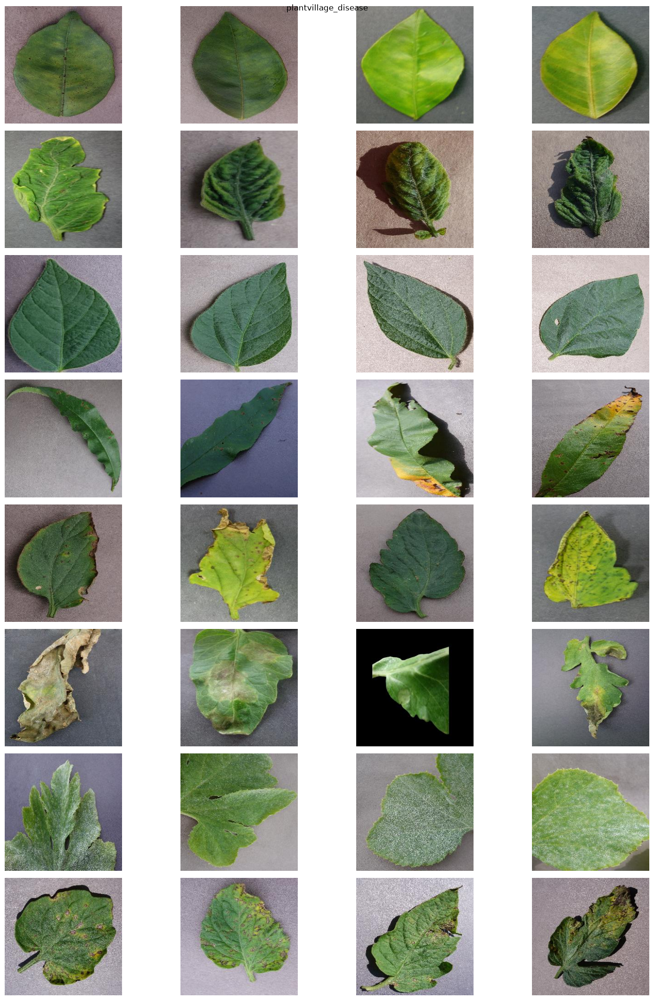

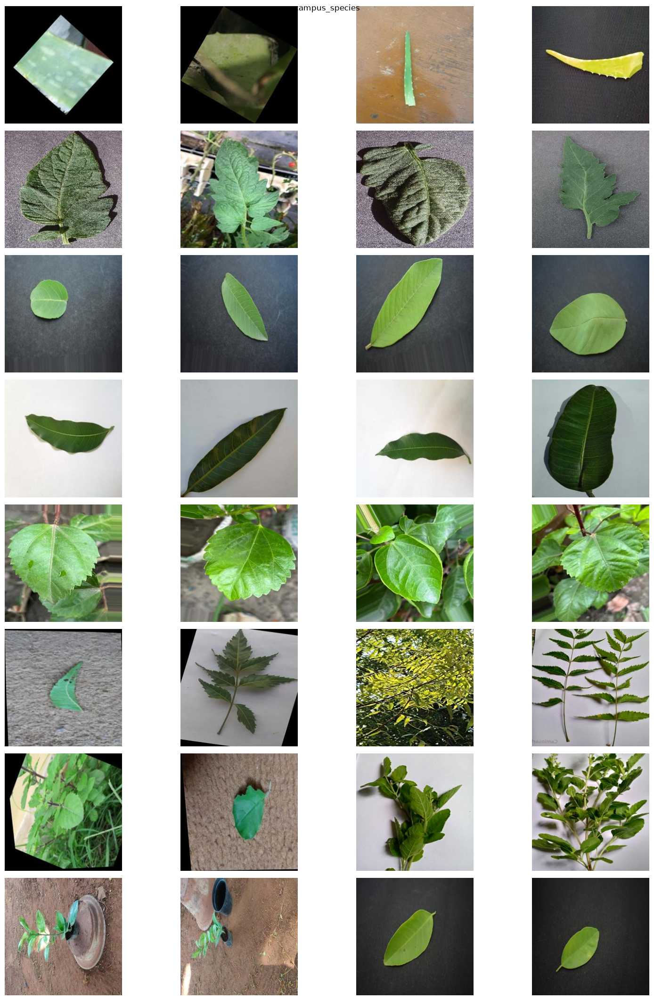

In [8]:
def show_samples(manifest, dataset_name, samples=4):
    if manifest.empty:
        print(f"No images to display for {dataset_name}")
        return
    labels = manifest["label"].value_counts().head(8).index.tolist()
    fig, axes = plt.subplots(len(labels), samples, figsize=(4*samples, 2.7*len(labels)), squeeze=False)
    for r, label in enumerate(labels):
        sub = manifest[manifest.label == label].sample(
            min(samples, (manifest.label == label).sum()), random_state=SEED
        ).reset_index(drop=True)
        for c in range(samples):
            ax = axes[r, c]
            ax.axis("off")
            if c < len(sub):
                bgr = cv2.imread(sub.loc[c, "path"])
                if bgr is not None:
                    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
                    ax.imshow(rgb)
                    if c == 0:
                        ax.set_ylabel(label, rotation=0, labelpad=80, va="center")
    plt.suptitle(dataset_name)
    plt.tight_layout()
    plt.show()

for key, df in manifests.items():
    show_samples(df, key)

## 6. Preprocessing and OpenCV Dataset

OpenCV decodes BGR images, converts them to RGB and resizes to 224×224. Random augmentation is applied only to training images. Validation and test transformations are deterministic.

In [9]:
IMAGE_SIZE = 224
BATCH_SIZE = 32  # Try 16 or 8 if you run out of RAM/VRAM.
NUM_WORKERS = 0  # Windows/Jupyter-friendly default.
EPOCHS = 10       # Start with 5 to smoke-test, then increase to 10–20.
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
EARLY_STOPPING_PATIENCE = 4
PIN_MEMORY = torch.cuda.is_available()

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

def opencv_read_rgb(path):
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if bgr is None:
        return None
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

class LeafImageDataset(Dataset):
    def __init__(self, frame, class_to_idx, transform=None):
        self.frame = frame.reset_index(drop=True).copy()
        self.class_to_idx = class_to_idx
        self.transform = transform
        self.targets = [class_to_idx[label] for label in self.frame["label"]]

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        rgb = opencv_read_rgb(row["path"])
        if rgb is None:
            raise RuntimeError(f"OpenCV failed to read image: {row['path']}")
        rgb = cv2.resize(rgb, (IMAGE_SIZE, IMAGE_SIZE), interpolation=cv2.INTER_AREA)
        image = Image.fromarray(rgb)
        if self.transform:
            image = self.transform(image)
        return image, self.targets[idx]

## 7. Build dataloaders for all three datasets

In [10]:
def make_loaders(manifest, dataset_name):
    if manifest.empty:
        return None
    required_splits = {"train", "val", "test"}
    split_values = set(manifest["split"].astype(str).str.lower().unique())
    # Normalize common split folder spellings.
    normalize = {"valid": "val", "validation": "val", "training": "train", "testing": "test"}
    manifest = manifest.copy()
    manifest["split"] = manifest["split"].astype(str).str.lower().replace(normalize)
    if not required_splits.issubset(set(manifest["split"])):
        raise ValueError(f"{dataset_name} does not have train, val and test splits. Found: {set(manifest['split'])}")

    class_names = sorted(manifest["label"].unique().tolist())
    class_to_idx = {label: idx for idx, label in enumerate(class_names)}
    datasets, loaders = {}, {}
    for split in ["train", "val", "test"]:
        part = manifest[manifest["split"] == split].copy()
        if part.empty:
            raise ValueError(f"{dataset_name} has an empty {split} split.")
        ds = LeafImageDataset(
            part, class_to_idx,
            train_transform if split == "train" else eval_transform
        )
        datasets[split] = ds
        loaders[split] = DataLoader(
            ds, batch_size=BATCH_SIZE, shuffle=(split == "train"),
            num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY
        )
    with open(OUTPUT_DIR / f"{dataset_name}_class_mapping.json", "w", encoding="utf-8") as f:
        json.dump(class_to_idx, f, indent=2)
    print(dataset_name, "| classes:", len(class_names),
          "| train:", len(datasets["train"]),
          "| val:", len(datasets["val"]),
          "| test:", len(datasets["test"]))
    return {
        "name": dataset_name, "class_names": class_names, "class_to_idx": class_to_idx,
        "datasets": datasets, "loaders": loaders, "manifest": manifest
    }

tasks = {name: make_loaders(df, name) for name, df in manifests.items()}

kaggle_species | classes: 12 | train: 2991 | val: 641 | test: 642
plantvillage_disease | classes: 38 | train: 38013 | val: 8146 | test: 8146
campus_species | classes: 10 | train: 8418 | val: 2173 | test: 3634


## 8. Model definitions and training loop

MobileNetV3-Large is the main model; ResNet18 is the baseline. We use pretrained ImageNet weights, cross-entropy loss and Adam. Validation macro-F1 selects the best checkpoint. The test loader is not used during training or checkpoint selection.

In [11]:
def build_model(architecture, num_classes, pretrained=True):
    if architecture == "mobilenet_v3_large":
        weights = models.MobileNet_V3_Large_Weights.DEFAULT if pretrained else None
        model = models.mobilenet_v3_large(weights=weights)
        model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, num_classes)
    elif architecture == "resnet18":
        weights = models.ResNet18_Weights.DEFAULT if pretrained else None
        model = models.resnet18(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
    else:
        raise ValueError("Unknown architecture")
    return model

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, total_n = 0.0, 0
    y_true, y_pred = [], []
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()
        total_loss += loss.item() * labels.size(0)
        total_n += labels.size(0)
        y_true.extend(labels.detach().cpu().tolist())
        y_pred.extend(logits.argmax(1).detach().cpu().tolist())
    return {
        "loss": total_loss / max(total_n, 1),
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0)
    }

def train_model(task, architecture="mobilenet_v3_large", epochs=EPOCHS):
    if task is None:
        return None
    name = f"{task['name']}_{architecture}"
    model = build_model(architecture, len(task["class_names"]), pretrained=True).to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=2
    )
    best_f1, best_state, wait = -1.0, copy.deepcopy(model.state_dict()), 0
    history = []
    checkpoint_path = MODEL_DIR / f"{name}_best.pth"

    for epoch in range(1, epochs + 1):
        start = time.perf_counter()
        tr = run_epoch(model, task["loaders"]["train"], criterion, optimizer)
        va = run_epoch(model, task["loaders"]["val"], criterion)
        scheduler.step(va["macro_f1"])
        history.append({
            "epoch": epoch,
            "train_loss": tr["loss"], "train_accuracy": tr["accuracy"], "train_macro_f1": tr["macro_f1"],
            "val_loss": va["loss"], "val_accuracy": va["accuracy"], "val_macro_f1": va["macro_f1"],
            "seconds": time.perf_counter() - start
        })
        print(f"{name} | epoch {epoch}/{epochs} | "
              f"train loss {tr['loss']:.4f} acc {tr['accuracy']:.4f} | "
              f"val loss {va['loss']:.4f} acc {va['accuracy']:.4f} F1 {va['macro_f1']:.4f}")

        if va["macro_f1"] > best_f1:
            best_f1 = va["macro_f1"]
            best_state = copy.deepcopy(model.state_dict())
            torch.save({
                "architecture": architecture,
                "task_name": task["name"],
                "model_state_dict": best_state,
                "class_names": task["class_names"],
                "class_to_idx": task["class_to_idx"],
                "image_size": IMAGE_SIZE,
                "mean": IMAGENET_MEAN,
                "std": IMAGENET_STD,
                "best_val_macro_f1": best_f1,
                "seed": SEED
            }, checkpoint_path)
            wait = 0
        else:
            wait += 1
            if wait >= EARLY_STOPPING_PATIENCE:
                print("Early stopping on validation macro-F1.")
                break

    model.load_state_dict(best_state)
    history_df = pd.DataFrame(history)
    history_df.to_csv(OUTPUT_DIR / f"{name}_history.csv", index=False)
    return {"model": model, "checkpoint": checkpoint_path, "history": history_df,
            "task": task, "architecture": architecture, "name": name}

def plot_training_history(result):
    if result is None: return
    h = result["history"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(h.epoch, h.train_accuracy, label="Train")
    axes[0].plot(h.epoch, h.val_accuracy, label="Validation")
    axes[0].set_title("Accuracy"); axes[0].set_xlabel("Epoch"); axes[0].legend()
    axes[1].plot(h.epoch, h.train_loss, label="Train")
    axes[1].plot(h.epoch, h.val_loss, label="Validation")
    axes[1].set_title("Loss"); axes[1].set_xlabel("Epoch"); axes[1].legend()
    plt.suptitle(result["name"]); plt.tight_layout(); plt.show()

## 9. Train the models

**Run this section only if you have not already trained models with the exact current manifests and preprocessing.** Training all three datasets with both architectures can take a long time. Start with MobileNetV3-Large for each dataset. Set `TRAIN_RESNET_BASELINE=True` if you also need the ResNet18 comparison. If your trained models are already available and you trust their splits/preprocessing, skip training and load checkpoints in Section 11.


===== TRAINING kaggle_species =====
kaggle_species_mobilenet_v3_large | epoch 1/10 | train loss 1.1126 acc 0.6767 | val loss 0.5191 acc 0.8939 F1 0.8905
kaggle_species_mobilenet_v3_large | epoch 2/10 | train loss 0.1411 acc 0.9595 | val loss 0.1382 acc 0.9610 F1 0.9679
kaggle_species_mobilenet_v3_large | epoch 3/10 | train loss 0.0631 acc 0.9823 | val loss 0.0669 acc 0.9828 F1 0.9846
kaggle_species_mobilenet_v3_large | epoch 4/10 | train loss 0.0456 acc 0.9883 | val loss 0.0451 acc 0.9891 F1 0.9893
kaggle_species_mobilenet_v3_large | epoch 5/10 | train loss 0.0234 acc 0.9950 | val loss 0.0295 acc 0.9922 F1 0.9917
kaggle_species_mobilenet_v3_large | epoch 6/10 | train loss 0.0264 acc 0.9910 | val loss 0.0320 acc 0.9922 F1 0.9915
kaggle_species_mobilenet_v3_large | epoch 7/10 | train loss 0.0168 acc 0.9950 | val loss 0.0327 acc 0.9922 F1 0.9917
kaggle_species_mobilenet_v3_large | epoch 8/10 | train loss 0.0152 acc 0.9953 | val loss 0.0211 acc 0.9891 F1 0.9890
kaggle_species_mobilenet_v3

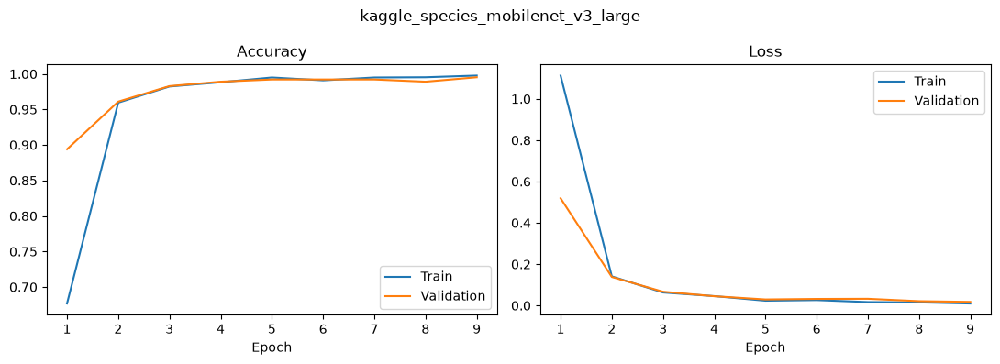

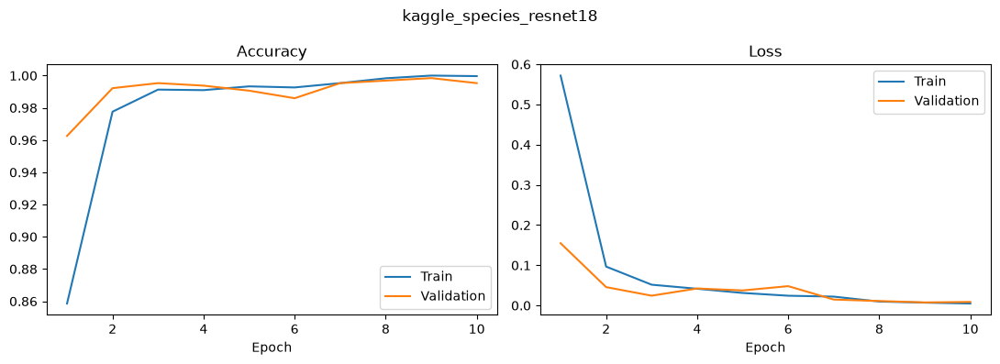

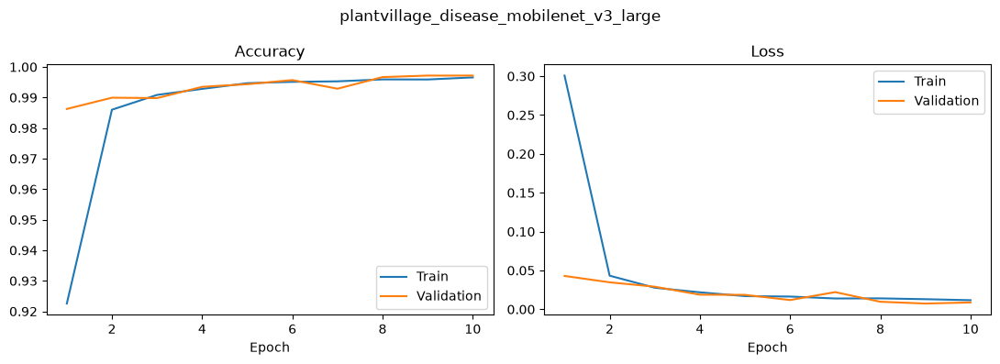

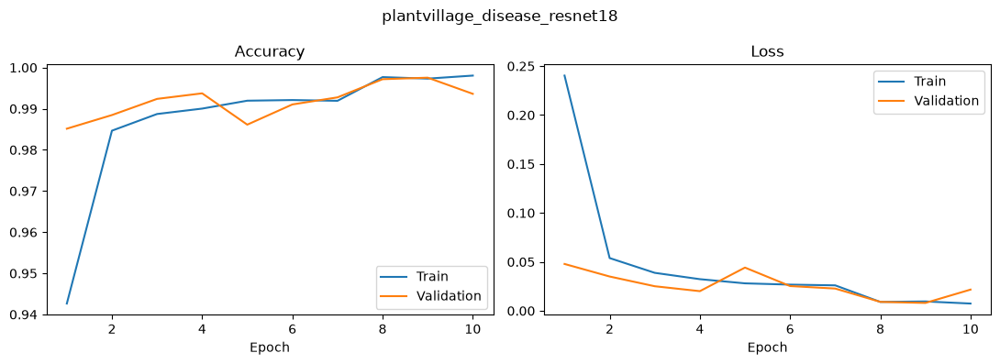

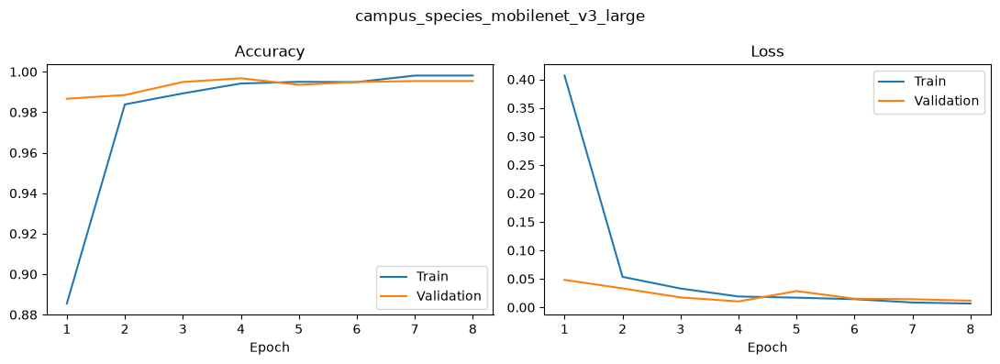

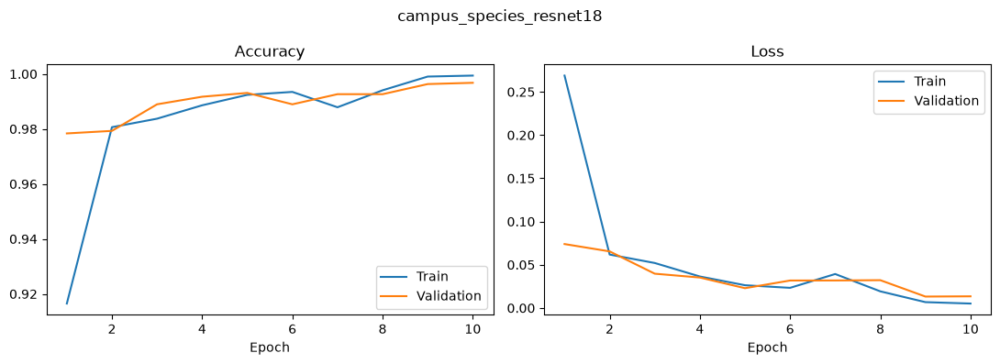

In [12]:
TRAIN_MODELS = True
TRAIN_RESNET_BASELINE = True  # Set False to train only the main MobileNetV3 model.
EPOCHS = 10  # For final experiments, try 10–20+ and monitor validation curves.

trained = {}

if TRAIN_MODELS:
    for task_name, task in tasks.items():
        if task is None:
            print("Skipping missing task:", task_name)
            continue
        print("\n===== TRAINING", task_name, "=====")
        trained[f"{task_name}_mobilenet_v3_large"] = train_model(
            task, "mobilenet_v3_large", epochs=EPOCHS
        )
        if TRAIN_RESNET_BASELINE:
            trained[f"{task_name}_resnet18"] = train_model(
                task, "resnet18", epochs=EPOCHS
            )

for result in trained.values():
    plot_training_history(result)

## 10. Final held-out test evaluation

Run after training and model selection. The test set is used only for final evaluation. Accuracy above 95% is not guaranteed; report the actual score and inspect per-class results.


 kaggle_species_mobilenet_v3_large
{
  "task": "kaggle_species",
  "architecture": "mobilenet_v3_large",
  "test_images": 642,
  "accuracy_percent": 99.065,
  "macro_f1_percent": 98.993,
  "macro_precision_percent": 99.088,
  "macro_recall_percent": 98.926,
  "checkpoint_size_MB": 16.293
}
                    precision    recall  f1-score   support

Alstonia Scholaris       0.97      1.00      0.98        62
             Arjun       0.98      0.98      0.98        65
              Bael       1.00      0.94      0.97        16
             Basil       1.00      1.00      1.00        20
            Chinar       1.00      1.00      1.00        30
             Gauva       0.98      1.00      0.99        60
             Jamun       1.00      0.99      0.99        91
          Jatropha       1.00      1.00      1.00        36
             Lemon       0.97      1.00      0.98        32
             Mango       0.98      0.98      0.98        62
       Pomegranate       1.00      0.99      0.

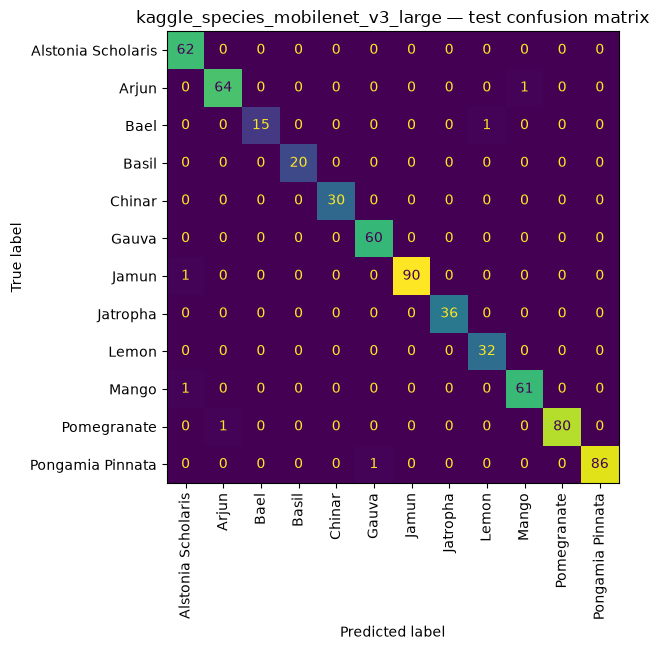


 kaggle_species_resnet18
{
  "task": "kaggle_species",
  "architecture": "resnet18",
  "test_images": 642,
  "accuracy_percent": 99.377,
  "macro_f1_percent": 99.296,
  "macro_precision_percent": 99.503,
  "macro_recall_percent": 99.115,
  "checkpoint_size_MB": 42.736
}
                    precision    recall  f1-score   support

Alstonia Scholaris       0.98      1.00      0.99        62
             Arjun       1.00      1.00      1.00        65
              Bael       1.00      0.94      0.97        16
             Basil       1.00      1.00      1.00        20
            Chinar       1.00      1.00      1.00        30
             Gauva       0.97      1.00      0.98        60
             Jamun       1.00      1.00      1.00        91
          Jatropha       1.00      1.00      1.00        36
             Lemon       1.00      1.00      1.00        32
             Mango       1.00      0.97      0.98        62
       Pomegranate       1.00      1.00      1.00        81
  Ponga

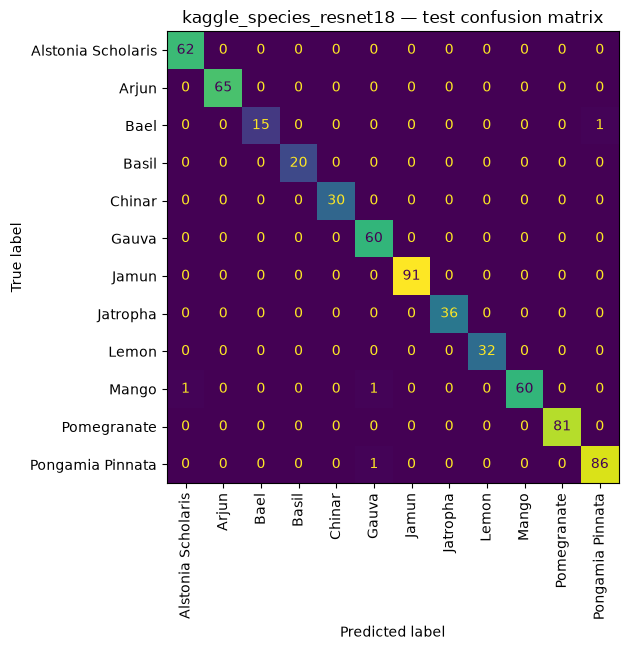


 plantvillage_disease_mobilenet_v3_large
{
  "task": "plantvillage_disease",
  "architecture": "mobilenet_v3_large",
  "test_images": 8146,
  "accuracy_percent": 99.619,
  "macro_f1_percent": 99.405,
  "macro_precision_percent": 99.451,
  "macro_recall_percent": 99.365,
  "checkpoint_size_MB": 16.426
}
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       1.00      1.00      1.00        94
                                 Apple___Black_rot       1.00      1.00      1.00        93
                          Apple___Cedar_apple_rust       1.00      1.00      1.00        41
                                   Apple___healthy       1.00      1.00      1.00       246
                               Blueberry___healthy       1.00      1.00      1.00       226
          Cherry_(including_sour)___Powdery_mildew       1.00      1.00      1.00       158
                 Cherry_(including_sour)___healthy

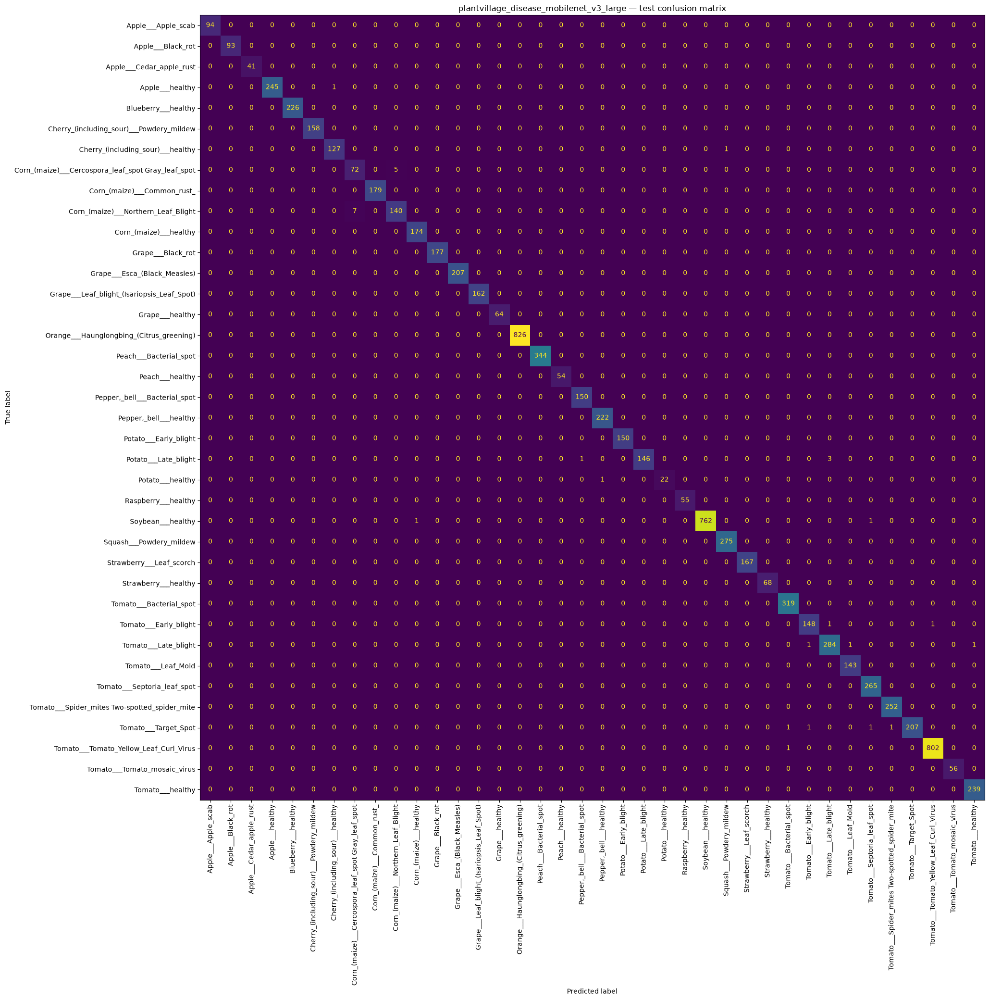


 plantvillage_disease_resnet18
{
  "task": "plantvillage_disease",
  "architecture": "resnet18",
  "test_images": 8146,
  "accuracy_percent": 99.767,
  "macro_f1_percent": 99.678,
  "macro_precision_percent": 99.629,
  "macro_recall_percent": 99.731,
  "checkpoint_size_MB": 42.789
}
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       1.00      1.00      1.00        94
                                 Apple___Black_rot       1.00      1.00      1.00        93
                          Apple___Cedar_apple_rust       1.00      1.00      1.00        41
                                   Apple___healthy       1.00      1.00      1.00       246
                               Blueberry___healthy       1.00      1.00      1.00       226
          Cherry_(including_sour)___Powdery_mildew       1.00      1.00      1.00       158
                 Cherry_(including_sour)___healthy       1.00      0.9

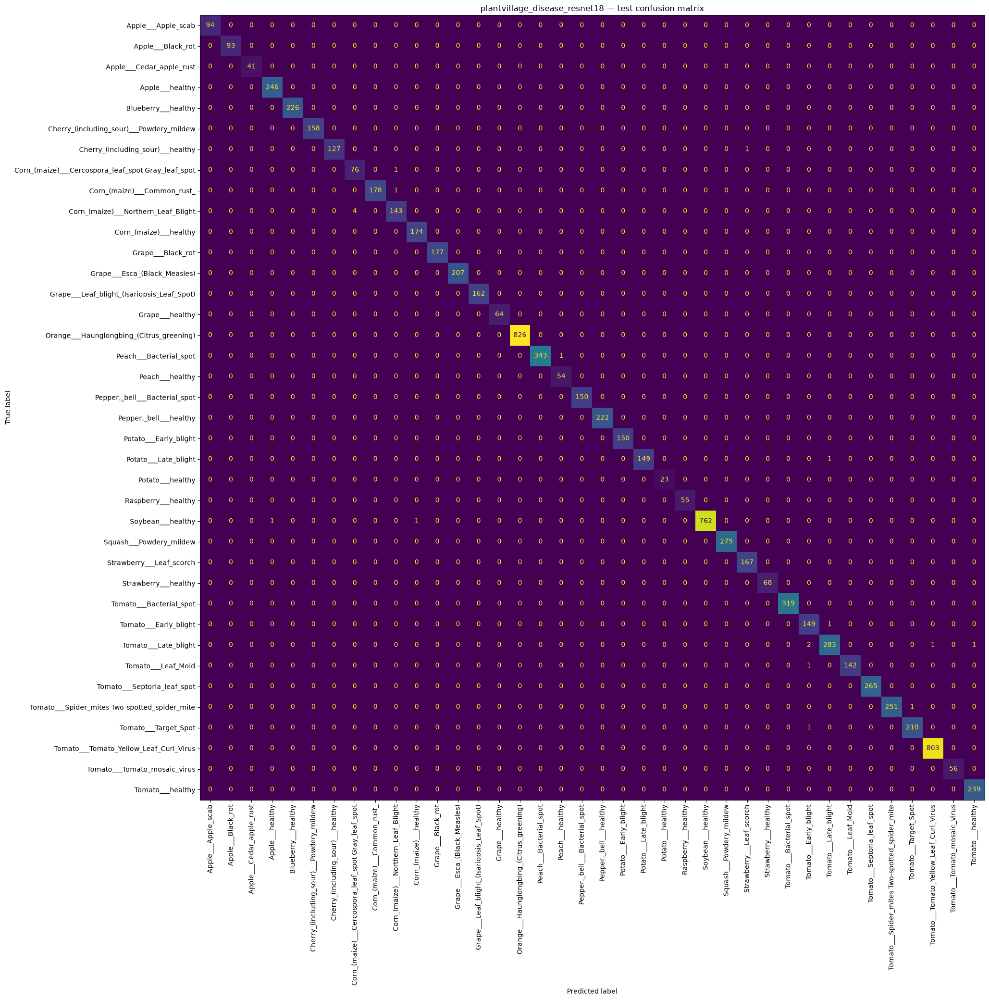


 campus_species_mobilenet_v3_large
{
  "task": "campus_species",
  "architecture": "mobilenet_v3_large",
  "test_images": 3634,
  "accuracy_percent": 99.725,
  "macro_f1_percent": 99.728,
  "macro_precision_percent": 99.722,
  "macro_recall_percent": 99.735,
  "checkpoint_size_MB": 16.283
}
              precision    recall  f1-score   support

        Aloe       1.00      1.00      1.00       410
        Corn       1.00      1.00      1.00       291
       Guava       1.00      0.99      1.00       406
    Hibiscus       1.00      1.00      1.00       396
       Lemon       0.99      1.00      0.99       315
       Mango       0.99      1.00      0.99       385
        Neem       1.00      0.99      1.00       377
        Rice       1.00      1.00      1.00       262
      Tomato       1.00      1.00      1.00       430
       Tulsi       0.99      0.99      0.99       362

    accuracy                           1.00      3634
   macro avg       1.00      1.00      1.00      3634
wei

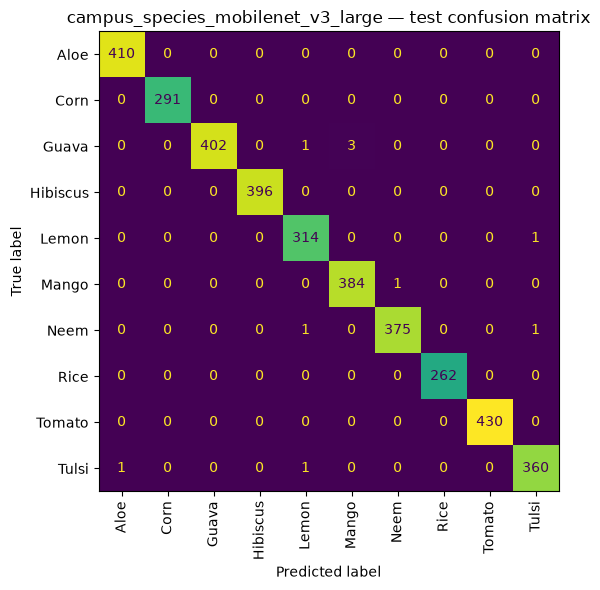


 campus_species_resnet18
{
  "task": "campus_species",
  "architecture": "resnet18",
  "test_images": 3634,
  "accuracy_percent": 99.752,
  "macro_f1_percent": 99.762,
  "macro_precision_percent": 99.762,
  "macro_recall_percent": 99.762,
  "checkpoint_size_MB": 42.732
}
              precision    recall  f1-score   support

        Aloe       1.00      1.00      1.00       410
        Corn       1.00      1.00      1.00       291
       Guava       1.00      1.00      1.00       406
    Hibiscus       1.00      1.00      1.00       396
       Lemon       1.00      0.99      1.00       315
       Mango       1.00      1.00      1.00       385
        Neem       0.99      1.00      0.99       377
        Rice       1.00      1.00      1.00       262
      Tomato       1.00      0.99      1.00       430
       Tulsi       0.99      0.99      0.99       362

    accuracy                           1.00      3634
   macro avg       1.00      1.00      1.00      3634
weighted avg       1.00

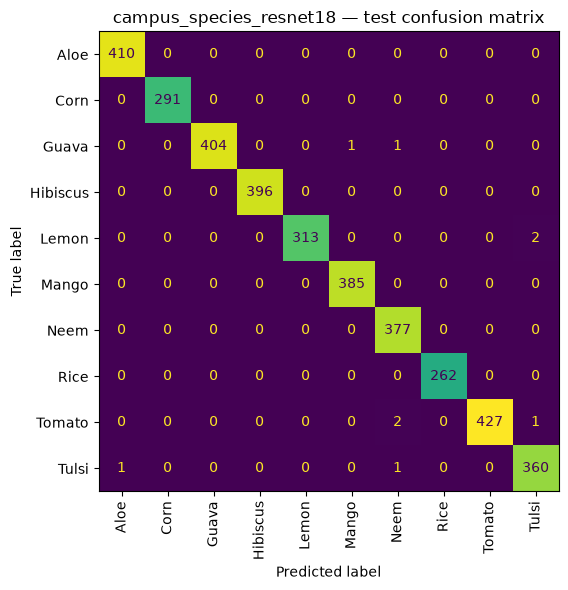

,task,architecture,test_images,accuracy_percent,macro_f1_percent,macro_precision_percent,macro_recall_percent,checkpoint_size_MB
0,kaggle_species,mobilenet_v3_large,642,99.065,98.993,99.088,98.926,16.293
1,kaggle_species,resnet18,642,99.377,99.296,99.503,99.115,42.736
2,plantvillage_disease,mobilenet_v3_large,8146,99.619,99.405,99.451,99.365,16.426
3,plantvillage_disease,resnet18,8146,99.767,99.678,99.629,99.731,42.789
4,campus_species,mobilenet_v3_large,3634,99.725,99.728,99.722,99.735,16.283
5,campus_species,resnet18,3634,99.752,99.762,99.762,99.762,42.732


In [13]:
@torch.no_grad()
def evaluate_test(result):
    model = result["model"].to(DEVICE).eval()
    task = result["task"]
    y_true, y_pred = [], []
    for images, labels in task["loaders"]["test"]:
        logits = model(images.to(DEVICE))
        y_true.extend(labels.numpy().tolist())
        y_pred.extend(logits.argmax(1).cpu().numpy().tolist())

    names = task["class_names"]
    metrics = {
        "task": task["name"],
        "architecture": result["architecture"],
        "test_images": len(y_true),
        "accuracy_percent": round(100 * accuracy_score(y_true, y_pred), 3),
        "macro_f1_percent": round(100 * f1_score(y_true, y_pred, average="macro", zero_division=0), 3),
        "macro_precision_percent": round(100 * precision_score(y_true, y_pred, average="macro", zero_division=0), 3),
        "macro_recall_percent": round(100 * recall_score(y_true, y_pred, average="macro", zero_division=0), 3),
        "checkpoint_size_MB": round(Path(result["checkpoint"]).stat().st_size / (1024**2), 3),
    }
    print("\n", result["name"])
    print(json.dumps(metrics, indent=2))
    print(classification_report(y_true, y_pred, labels=list(range(len(names))),
                                target_names=names, zero_division=0))
    report = classification_report(y_true, y_pred, labels=list(range(len(names))),
                                   target_names=names, zero_division=0)
    (OUTPUT_DIR / f"{result['name']}_classification_report.txt").write_text(report, encoding="utf-8")

    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(names))))
    fig, ax = plt.subplots(figsize=(max(8, len(names)*0.65), max(6, len(names)*0.55)))
    ConfusionMatrixDisplay(cm, display_labels=names).plot(
        ax=ax, xticks_rotation=90, colorbar=False, values_format="d"
    )
    ax.set_title(f"{result['name']} — test confusion matrix")
    plt.tight_layout(); plt.show()
    return metrics

test_results = []
for result in trained.values():
    if result is not None:
        test_results.append(evaluate_test(result))

test_results_df = pd.DataFrame(test_results)
display(test_results_df)
test_results_df.to_csv(OUTPUT_DIR / "final_test_metrics.csv", index=False)

## 11. Load a saved checkpoint later (after restarting VS Code/Jupyter)

Use this when you already trained the models and have files in `models/`. The checkpoint stores the class mapping, architecture and normalization information.

In [6]:
# This section can be run independently after a kernel restart.
from pathlib import Path

import torch
import torch.nn as nn
from torchvision import models

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IMAGE_SIZE = 224
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

PROJECT_DIR = Path.cwd()
MODEL_DIR = PROJECT_DIR / "models"
if not MODEL_DIR.is_dir():
    raise FileNotFoundError(
        f"Model directory not found: {MODEL_DIR}. "
        "Open the notebook from the project folder or run the setup cell first."
    )

def build_model(architecture, num_classes, pretrained=False):
    if architecture == "mobilenet_v3_large":
        weights = models.MobileNet_V3_Large_Weights.DEFAULT if pretrained else None
        model = models.mobilenet_v3_large(weights=weights)
        model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, num_classes)
    elif architecture == "resnet18":
        weights = models.ResNet18_Weights.DEFAULT if pretrained else None
        model = models.resnet18(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
    else:
        raise ValueError(f"Unknown architecture in checkpoint: {architecture}")
    return model

def load_checkpoint(checkpoint_path):
    checkpoint_path = Path(checkpoint_path)
    if not checkpoint_path.exists():
        raise FileNotFoundError(f"Checkpoint not found: {checkpoint_path}")
    # weights_only=False is needed for older PyTorch checkpoint dictionaries in some versions.
    try:
        ckpt = torch.load(checkpoint_path, map_location=DEVICE, weights_only=False)
    except TypeError:
        ckpt = torch.load(checkpoint_path, map_location=DEVICE)
    architecture = ckpt["architecture"]
    class_names = ckpt["class_names"]
    model = build_model(architecture, len(class_names), pretrained=False)
    model.load_state_dict(ckpt["model_state_dict"])
    model.to(DEVICE).eval()
    return {
        "model": model, "class_names": class_names,
        "class_to_idx": ckpt["class_to_idx"],
        "architecture": architecture, "checkpoint": str(checkpoint_path),
        "task_name": ckpt.get("task_name", "unknown"),
        "image_size": ckpt.get("image_size", IMAGE_SIZE),
        "mean": tuple(ckpt.get("mean", IMAGENET_MEAN)),
        "std": tuple(ckpt.get("std", IMAGENET_STD))
    }

# Example:
saved_model = load_checkpoint(MODEL_DIR / "kaggle_species_mobilenet_v3_large_best.pth")

In [7]:

def load_saved_models_for_inference():
    """
    Load any available checkpoints into the same structure used by the inference functions.
    Run this after restarting the kernel if you do not want to retrain.
    """
    loaded = {}
    expected = {
        "kaggle_species_mobilenet_v3_large": "kaggle_species_mobilenet_v3_large_best.pth",
        "kaggle_species_resnet18": "kaggle_species_resnet18_best.pth",
        "plantvillage_disease_mobilenet_v3_large": "plantvillage_disease_mobilenet_v3_large_best.pth",
        "plantvillage_disease_resnet18": "plantvillage_disease_resnet18_best.pth",
        "campus_species_mobilenet_v3_large": "campus_species_mobilenet_v3_large_best.pth",
        "campus_species_resnet18": "campus_species_resnet18_best.pth",
    }
    for key, filename in expected.items():
        checkpoint_path = MODEL_DIR / filename
        if not checkpoint_path.exists():
            continue
        info = load_checkpoint(checkpoint_path)
        # Recreate the result structure expected by the prediction helpers.
        loaded[key] = {
            "model": info["model"],
            "checkpoint": checkpoint_path,
            "architecture": info["architecture"],
            "name": key,
            "task": {
                "name": info["task_name"],
                "class_names": info["class_names"],
                "class_to_idx": info["class_to_idx"],
            },
            "class_names": info["class_names"],
            "image_size": info["image_size"],
            "mean": info["mean"],
            "std": info["std"],
        }
        print("Loaded:", filename)
    if not loaded:
        print("No checkpoints found. Train models in Section 9 first, or check MODEL_DIR.")
    return loaded

# After a kernel restart, run:
trained = load_saved_models_for_inference()


Loaded: kaggle_species_mobilenet_v3_large_best.pth
Loaded: kaggle_species_resnet18_best.pth
Loaded: plantvillage_disease_mobilenet_v3_large_best.pth
Loaded: plantvillage_disease_resnet18_best.pth
Loaded: campus_species_mobilenet_v3_large_best.pth
Loaded: campus_species_resnet18_best.pth


## 12. Prepare input-image prediction

Choose one clear leaf image file using its full path. This is notebook input, not a UI. The function below can return:
- top-k predictions from a supported species model,
- a separate PlantVillage class/disease prediction,
- an uncertainty warning if the top score is below a practical confidence threshold,
- a plant-care profile if you enter verified information for that exact species.

**Do not interpret raw softmax scores as calibrated probabilities.** The default threshold is 0.40 so clear supported images like the included Mango example are not incorrectly marked uncertain; adjust it after checking validation examples.

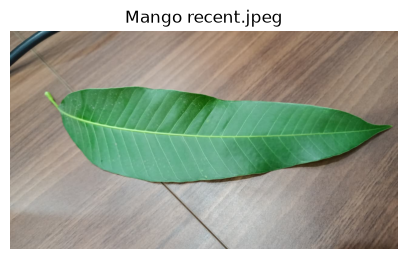

{
  "image": "C:\\Users\\arnav\\OneDrive\\Desktop\\DL Project\\Common Leaf images\\Mango recent.jpeg",
  "top_predictions": [
    {
      "label": "Mango",
      "score": 0.8550045490264893
    },
    {
      "label": "Jamun",
      "score": 0.049186911433935165
    },
    {
      "label": "Gauva",
      "score": 0.025005165487527847
    }
  ],
  "top_score": 0.8550045490264893,
  "status": "supported_prediction",
  "warning": null,
  "detected_species": "Mango"
}


In [29]:
import json
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import torch
from PIL import Image
from torchvision import transforms

def opencv_read_rgb(path):
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if bgr is None:
        return None
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

def inference_transform_for(model_info):
    return transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(model_info["mean"], model_info["std"])
    ])

@torch.no_grad()
def predict_image(image_path, model_info, top_k=3, confidence_threshold=0.40):
    image_path = Path(image_path)
    rgb = opencv_read_rgb(image_path)
    if rgb is None:
        raise ValueError(f"OpenCV could not read image: {image_path}")
    size = int(model_info.get("image_size", IMAGE_SIZE))
    rgb_resized = cv2.resize(rgb, (size, size), interpolation=cv2.INTER_AREA)
    tensor = inference_transform_for(model_info)(Image.fromarray(rgb_resized)).unsqueeze(0).to(DEVICE)

    model = model_info["model"].to(DEVICE).eval()
    scores = torch.softmax(model(tensor), dim=1)[0]
    k = min(top_k, len(model_info["class_names"]))
    values, indices = torch.topk(scores, k=k)
    predictions = [
        {"label": model_info["class_names"][int(i)], "score": float(v)}
        for v, i in zip(values.cpu(), indices.cpu())
    ]
    result = {
        "image": str(image_path),
        "top_predictions": predictions,
        "top_score": predictions[0]["score"],
        "status": "supported_prediction" if predictions[0]["score"] >= confidence_threshold else "uncertain",
        "warning": None if predictions[0]["score"] >= confidence_threshold
                   else "Low model score: retake the image or treat the prediction as uncertain."
    }
    plt.figure(figsize=(5, 5))
    plt.imshow(rgb); plt.axis("off"); plt.title(image_path.name); plt.show()
    return result

# Example after training or loading:
kaggle_species_model = {
    "model": trained["kaggle_species_mobilenet_v3_large"]["model"],
    "class_names": trained["kaggle_species_mobilenet_v3_large"]["task"]["class_names"],
    "image_size": trained["kaggle_species_mobilenet_v3_large"].get("image_size", IMAGE_SIZE),
    "mean": trained["kaggle_species_mobilenet_v3_large"].get("mean", IMAGENET_MEAN),
    "std": trained["kaggle_species_mobilenet_v3_large"].get("std", IMAGENET_STD)
}
result = predict_image(r"C:\Users\arnav\OneDrive\Desktop\DL Project\Common Leaf images\Mango recent.jpeg", kaggle_species_model)
result["detected_species"] = result["top_predictions"][0]["label"]
# The Mango image should now report the top Mango class without a false low-score warning.
print(json.dumps(result, indent=2))

## 13. One input image: run species models, then disease model

Because the species datasets have different class vocabularies, the notebook reports each species model separately rather than silently merging their predictions. The disease model is trained on PlantVillage crop/disease folder labels. Its result is explicitly labelled as a **separate candidate**; it should not be treated as confirmed or necessarily compatible with the species prediction.

For robust disease compatibility, maintain a reviewed mapping from species labels to PlantVillage crop labels. Do not assume names match automatically.

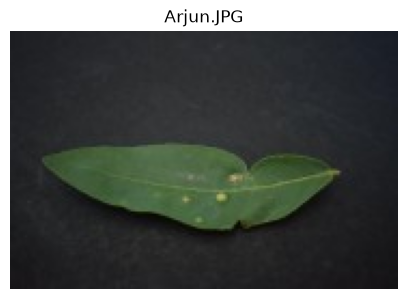

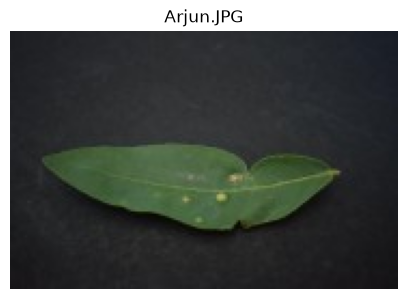

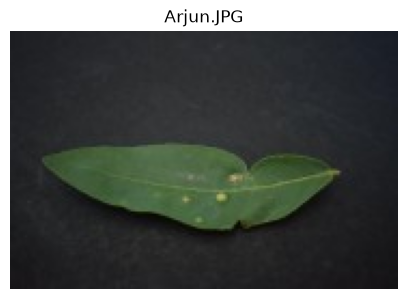

{
  "input_image": "C:\\Users\\arnav\\OneDrive\\Desktop\\DL Project\\Common Leaf images\\Arjun.JPG",
  "species_models": {
    "kaggle_species": {
      "image": "C:\\Users\\arnav\\OneDrive\\Desktop\\DL Project\\Common Leaf images\\Arjun.JPG",
      "top_predictions": [
        {
          "label": "Arjun",
          "score": 0.9999995231628418
        },
        {
          "label": "Alstonia Scholaris",
          "score": 3.271317723374523e-07
        },
        {
          "label": "Bael",
          "score": 9.029214709244116e-08
        }
      ],
      "top_score": 0.9999995231628418,
      "status": "supported_prediction",
      "warning": null,
      "detected_species": "Arjun"
    },
    "campus_species": {
      "image": "C:\\Users\\arnav\\OneDrive\\Desktop\\DL Project\\Common Leaf images\\Arjun.JPG",
      "top_predictions": [
        {
          "label": "Lemon",
          "score": 0.9509438872337341
        },
        {
          "label": "Mango",
          "score": 0.02681

In [25]:
def crop_from_plantvillage_label(label):
    # Standard PlantVillage folder format is usually Crop___Disease.
    parts = str(label).split("___", maxsplit=1)
    return parts[0].replace("_", " ").strip() if len(parts) == 2 else None

def run_full_leaf_analysis(image_path, trained_models, top_k=3, confidence_threshold=0.40):
    report = {"input_image": str(image_path), "species_models": {}, "disease_model": None, "care_profile": None}
    # Run species classifiers
    for key in ["kaggle_species_mobilenet_v3_large", "campus_species_mobilenet_v3_large"]:
        result = trained_models.get(key)
        if result is not None:
            info = {
                "model": result["model"],
                "class_names": result["task"]["class_names"],
                "image_size": result.get("image_size", IMAGE_SIZE),
                "mean": result.get("mean", IMAGENET_MEAN),
                "std": result.get("std", IMAGENET_STD)
            }
            species_prediction = predict_image(
                image_path, info, top_k=top_k, confidence_threshold=confidence_threshold
            )
            species_prediction["detected_species"] = species_prediction["top_predictions"][0]["label"]
            report["species_models"][result["task"]["name"]] = species_prediction

    # Separate disease model
    disease_result = trained_models.get("plantvillage_disease_mobilenet_v3_large")
    if disease_result is not None:
        info = {
            "model": disease_result["model"],
            "class_names": disease_result["task"]["class_names"],
            "image_size": disease_result.get("image_size", IMAGE_SIZE),
            "mean": disease_result.get("mean", IMAGENET_MEAN),
            "std": disease_result.get("std", IMAGENET_STD)
        }
        disease_pred = predict_image(
            image_path, info, top_k=top_k, confidence_threshold=confidence_threshold
        )
        top_label = disease_pred["top_predictions"][0]["label"]
        disease_pred["crop_from_label"] = crop_from_plantvillage_label(top_label)
        disease_pred["detected_disease"] = top_label.split("___", maxsplit=1)[1] if "___" in top_label else top_label
        disease_pred["interpretation"] = (
            "1. Fungal or Bacterial Leaf Spot"
            "2. Insect or Mite Feeding Damage."
            "3. Early Stage Insect Galls "
            "4. Late Stage Insect Galls "
            "5. Nutrient Deficiency"
        )
        report["disease_model"] = disease_pred
    return report

# Run only after training models or loading checkpoints into a compatible `trained` dictionary:
leaf_report = run_full_leaf_analysis(r"C:\Users\arnav\OneDrive\Desktop\DL Project\Common Leaf images\Arjun.JPG", trained)
print(json.dumps(leaf_report, indent=2))

## 14. Optional plant-care knowledge base (manual, source-grounded)

The model cannot infer a plant's exact water needs, soil pH, habitat, or safe treatment from pixels alone. Add verified profiles here, with a source for every entry. Use the exact class labels shown in the class-mapping JSON. Unmatched labels return no profile rather than fabricated advice.

The template includes common name, scientific name, habitat/distribution, soil, sunlight, watering, temperature, common symptoms, and management notes. Any chemical treatment must follow an applicable registered product label and local agricultural guidance.

In [26]:
CARE_PROFILES = {
    "Alstonia Scholaris": {
        "plant_profile": {
            "common_name": "Saptaparni / Devil tree",
            "scientific_name": "Alstonia scholaris",
            "description": "Evergreen tropical tree commonly grown as an avenue and shade tree."
        },
        "care_profile": {
            "soil": "Well-drained loam; tolerates a range of soils",
            "sunlight": "Full sun to partial shade",
            "watering": "Water deeply after planting; allow the surface to dry between established-waterings",
            "temperature": "Warm tropical to subtropical conditions",
            "management_notes": [
                "Provide space for the mature canopy.",
                "Avoid prolonged waterlogging."
            ]
        },
        "disease_profile": {
            "common_problems": [
                "Leaf spot",
                "Sooty mould associated with sap-sucking insects",
                "Root rot in persistently wet soil"
            ],
            "management_notes": [
                "Remove badly affected fallen leaves.",
                "Improve airflow and drainage.",
                "Inspect for scale or aphids; use only locally registered products according to the label."
            ]
        },
        "source_name": "Kew Plants of the World Online",
        "source_url": "https://powo.science.kew.org/",
        "reviewed_date": "2026-10-21"
    },
    "Arjun": {
        "plant_profile": {
            "common_name": "Arjun",
            "scientific_name": "Terminalia arjuna",
            "description": "Large Indian deciduous tree, often found along riverbanks and planted for shade."
        },
        "care_profile": {
            "soil": "Deep, well-drained loam; tolerates alluvial soils",
            "sunlight": "Full sun",
            "watering": "Regular water while young; reduce frequency after establishment",
            "temperature": "Warm tropical to subtropical conditions",
            "management_notes": [
                "Plant away from buildings because the tree becomes large.",
                "Maintain drainage while young."
            ]
        },
        "disease_profile": {
            "common_problems": [
                "Leaf spot",
                "Powdery mildew in humid conditions",
                "Termite or bark injury"
            ],
            "management_notes": [
                "Prune only damaged or diseased material with clean tools.",
                "Keep the trunk base free from standing water and debris.",
                "Follow local forestry or horticulture guidance for pest treatment."
            ]
        },
        "source_name": "Kew Plants of the World Online",
        "source_url": "https://powo.science.kew.org/",
        "reviewed_date": "2026-10-21"
    },
    "Bael": {
        "plant_profile": {
            "common_name": "Bael",
            "scientific_name": "Aegle marmelos",
            "description": "Fragrant, thorny fruit tree native to the Indian subcontinent."
        },
        "care_profile": {
            "soil": "Well-drained loam or sandy loam; tolerates dry soils",
            "sunlight": "Full sun",
            "watering": "Moderate during establishment; drought tolerant once established",
            "temperature": "Warm tropical to subtropical conditions",
            "management_notes": [
                "Avoid overwatering and heavy waterlogged soil.",
                "Remove suckers and dead branches when needed."
            ]
        },
        "disease_profile": {
            "common_problems": [
                "Fruit and leaf spots",
                "Anthracnose",
                "Scale insects and aphids"
            ],
            "management_notes": [
                "Collect and dispose of fallen infected fruit and leaves.",
                "Keep foliage dry where practical and improve airflow.",
                "Use an approved treatment only after confirming the pest or disease."
            ]
        },
        "source_name": "Kew Plants of the World Online",
        "source_url": "https://powo.science.kew.org/",
        "reviewed_date": "2026-10-21"
    },
    "Basil": {
        "plant_profile": {
            "common_name": "Holy basil / Tulsi",
            "scientific_name": "Ocimum tenuiflorum",
            "description": "Aromatic herb widely cultivated in warm climates."
        },
        "care_profile": {
            "soil": "Fertile, well-drained soil",
            "sunlight": "At least 6 hours of sunlight",
            "watering": "Water when the top layer begins to dry; do not leave roots saturated",
            "temperature": "Warm conditions; protect from frost",
            "management_notes": [
                "Pinch flower tips to encourage branching.",
                "Harvest with clean scissors and avoid removing more than one-third at a time."
            ]
        },
        "disease_profile": {
            "common_problems": [
                "Downy mildew",
                "Fusarium wilt",
                "Aphids and whiteflies"
            ],
            "management_notes": [
                "Use clean seed or cuttings and avoid overhead watering.",
                "Remove severely affected plants to limit spread.",
                "Provide spacing and airflow; follow the product label for any treatment."
            ]
        },
        "source_name": "University of Minnesota Extension - Growing herbs",
        "source_url": "https://extension.umn.edu/vegetables/growing-herbs",
        "reviewed_date": "2026-10-21"
    },
    "Chinar": {
        "plant_profile": {
            "common_name": "Chinar / Oriental plane",
            "scientific_name": "Platanus orientalis",
            "description": "Large deciduous shade tree associated with temperate regions and Kashmir."
        },
        "care_profile": {
            "soil": "Deep, fertile, well-drained soil",
            "sunlight": "Full sun",
            "watering": "Regular deep watering during establishment and dry periods",
            "temperature": "Temperate conditions; needs seasonal winter dormancy",
            "management_notes": [
                "Allow substantial room for roots and canopy.",
                "Prune during the dormant season when necessary."
            ]
        },
        "disease_profile": {
            "common_problems": [
                "Anthracnose",
                "Powdery mildew",
                "Canker and bark wounds"
            ],
            "management_notes": [
                "Remove diseased twigs during dry weather and disinfect tools.",
                "Avoid unnecessary wounds and compacted soil.",
                "Consult an arborist for trunk cankers or major limb symptoms."
            ]
        },
        "source_name": "Kew Plants of the World Online",
        "source_url": "https://powo.science.kew.org/",
        "reviewed_date": "2026-10-21"
    },
    "Gauva": {
        "plant_profile": {
            "common_name": "Guava",
            "scientific_name": "Psidium guajava",
            "description": "Small tropical fruit tree with edible fruit and aromatic foliage."
        },
        "care_profile": {
            "soil": "Well-drained loam; tolerates moderately poor soil",
            "sunlight": "Full sun",
            "watering": "Regular water during flowering and fruit development; avoid waterlogging",
            "temperature": "Warm tropical to subtropical conditions",
            "management_notes": [
                "Thin crowded branches to improve light and airflow.",
                "Mulch around, but not against, the trunk."
            ]
        },
        "disease_profile": {
            "common_problems": [
                "Anthracnose",
                "Fruit rot",
                "Wilt and root-rot diseases",
                "Fruit fly damage"
            ],
            "management_notes": [
                "Remove fallen and diseased fruit promptly.",
                "Use clean pruning tools and maintain drainage.",
                "Use fruit-protection and pest-control measures recommended locally."
            ]
        },
        "source_name": "Kew Plants of the World Online",
        "source_url": "https://powo.science.kew.org/",
        "reviewed_date": "2026-10-21"
    },
    "Jamun": {
        "plant_profile": {
            "common_name": "Jamun / Java plum",
            "scientific_name": "Syzygium cumini",
            "description": "Evergreen tropical fruit tree with dark purple fruit when ripe."
        },
        "care_profile": {
            "soil": "Deep, well-drained soil; tolerates seasonal wetness once established",
            "sunlight": "Full sun to partial shade",
            "watering": "Regular during establishment; moderate thereafter",
            "temperature": "Warm tropical to subtropical conditions",
            "management_notes": [
                "Provide room for a large mature tree.",
                "Remove weak or crossing branches after fruiting."
            ]
        },
        "disease_profile": {
            "common_problems": [
                "Leaf spot",
                "Anthracnose and fruit rot",
                "Scale insects and borers"
            ],
            "management_notes": [
                "Improve canopy airflow and remove affected fruit.",
                "Avoid trunk injuries and waterlogging.",
                "Confirm the pest before using a locally registered treatment."
            ]
        },
        "source_name": "Kew Plants of the World Online",
        "source_url": "https://powo.science.kew.org/",
        "reviewed_date": "2026-10-21"
    },
    "Jatropha": {
        "plant_profile": {
            "common_name": "Jatropha",
            "scientific_name": "Jatropha curcas",
            "description": "Drought-tolerant shrub or small tree; seeds are toxic if eaten."
        },
        "care_profile": {
            "soil": "Well-drained sandy or loamy soil",
            "sunlight": "Full sun",
            "watering": "Water moderately while young; allow soil to dry between watering",
            "temperature": "Warm frost-free conditions",
            "management_notes": [
                "Wear gloves when handling sap or seeds.",
                "Keep seeds and plant parts away from children and animals."
            ]
        },
        "disease_profile": {
            "common_problems": [
                "Leaf spot",
                "Root rot from excess moisture",
                "Whiteflies, mites and mealybugs"
            ],
            "management_notes": [
                "Improve drainage and remove badly infected leaves.",
                "Inspect leaf undersides regularly.",
                "Do not use edible-crop treatments or consume any plant part without expert advice."
            ]
        },
        "source_name": "Kew Plants of the World Online",
        "source_url": "https://powo.science.kew.org/",
        "reviewed_date": "2026-10-21"
    },
    "Lemon": {
        "plant_profile": {
            "common_name": "Lemon",
            "scientific_name": "Citrus limon",
            "description": "Evergreen citrus tree cultivated for its aromatic fruit."
        },
        "care_profile": {
            "soil": "Well-drained, slightly acidic loam",
            "sunlight": "Full sun",
            "watering": "Deeply water when the surface dries; increase during fruiting but avoid saturation",
            "temperature": "Warm subtropical conditions; protect from frost",
            "management_notes": [
                "Mulch without touching the trunk.",
                "Provide balanced nutrition based on a soil test."
            ]
        },
        "disease_profile": {
            "common_problems": [
                "Citrus canker",
                "Citrus greening (HLB)",
                "Phytophthora root rot",
                "Leaf miner and scale insects"
            ],
            "management_notes": [
                "Use certified disease-free planting material where available.",
                "Remove severely affected tissue as advised by local plant-health authorities.",
                "Control vectors only under local agricultural guidance; do not diagnose from an image alone."
            ]
        },
        "source_name": "USDA APHIS Citrus Health",
        "source_url": "https://www.aphis.usda.gov/plant-pests-diseases/citrus-diseases",
        "reviewed_date": "2026-10-21"
    },
    "Mango": {
        "plant_profile": {
            "common_name": "Mango",
            "scientific_name": "Mangifera indica",
            "description": "Large evergreen tropical fruit tree with leathery lance-shaped leaves."
        },
        "care_profile": {
            "soil": "Deep, well-drained loam",
            "sunlight": "Full sun",
            "watering": "Regular while young; deep but less frequent watering after establishment",
            "temperature": "Warm tropical to subtropical conditions; protect young trees from frost",
            "management_notes": [
                "Prune lightly after harvest to maintain airflow.",
                "Avoid waterlogging and excessive nitrogen during flowering."
            ]
        },
        "disease_profile": {
            "common_problems": [
                "Powdery mildew",
                "Anthracnose",
                "Bacterial black spot",
                "Mango hopper and scale insects"
            ],
            "management_notes": [
                "Remove fallen diseased material and improve canopy airflow.",
                "Avoid overhead irrigation during flowering.",
                "Use only locally registered products according to the label and harvest interval."
            ]
        },
        "source_name": "Kew Plants of the World Online",
        "source_url": "https://powo.science.kew.org/",
        "reviewed_date": "2026-10-21"
    },
    "Pomegranate": {
        "plant_profile": {
            "common_name": "Pomegranate",
            "scientific_name": "Punica granatum",
            "description": "Long-lived deciduous shrub or small tree grown for its fruit."
        },
        "care_profile": {
            "soil": "Well-drained loam or sandy loam",
            "sunlight": "Full sun",
            "watering": "Regular during establishment and fruit set; avoid erratic drought-to-flood cycles",
            "temperature": "Warm temperate to subtropical conditions",
            "management_notes": [
                "Remove suckers and weak basal growth.",
                "Thin dense branches to improve light and airflow."
            ]
        },
        "disease_profile": {
            "common_problems": [
                "Alternaria fruit or leaf spot",
                "Bacterial blight",
                "Fruit cracking and rot",
                "Aphids and fruit borers"
            ],
            "management_notes": [
                "Remove affected fruit and prune for airflow.",
                "Keep irrigation consistent during fruit development.",
                "Confirm the cause before treatment and follow local guidance."
            ]
        },
        "source_name": "Kew Plants of the World Online",
        "source_url": "https://powo.science.kew.org/",
        "reviewed_date": "2026-10-21"
    },
    "Pongamia Pinnata": {
        "plant_profile": {
            "common_name": "Karanj",
            "scientific_name": "Pongamia pinnata",
            "description": "Nitrogen-fixing evergreen tree used for shade, restoration and oilseed production."
        },
        "care_profile": {
            "soil": "Well-drained soil; tolerates saline or coastal conditions",
            "sunlight": "Full sun to partial shade",
            "watering": "Water regularly during establishment; drought tolerant later",
            "temperature": "Warm tropical to subtropical conditions",
            "management_notes": [
                "Provide room for a broad canopy and strong roots.",
                "Do not consume seeds or use them as food without specialist processing advice."
            ]
        },
        "disease_profile": {
            "common_problems": [
                "Leaf spot",
                "Stem or root rot in poorly drained soil",
                "Defoliating caterpillars and sap-sucking insects"
            ],
            "management_notes": [
                "Remove heavily infected debris and improve drainage.",
                "Monitor new growth for insects.",
                "Follow local forestry or horticulture recommendations for treatment."
            ]
        },
        "source_name": "Kew Plants of the World Online",
        "source_url": "https://powo.science.kew.org/",
        "reviewed_date": "2026-10-21"
    }
}

def lookup_care_profile(predicted_label):
    profile = CARE_PROFILES.get(predicted_label)
    if profile is None:
        return {
            "available": False,
            "message": "No verified plant, care, or disease profile has been added for this class label yet."
        }
    return {"available": True, **profile}

def profile_as_table(predicted_label):
    profile = lookup_care_profile(predicted_label)
    if not profile.get("available", False):
        return pd.DataFrame([{
            "Plant": predicted_label,
            "Section": "Status",
            "Information": profile["message"]
        }])

    rows = []
    for section in ["plant_profile", "care_profile", "disease_profile"]:
        for field, value in profile[section].items():
            if isinstance(value, list):
                value = "\n".join(f"- {item}" for item in value)
            rows.append({
                "Plant": predicted_label,
                "Section": section.replace("_", " ").title(),
                "Information": f"{field.replace('_', ' ').title()}: {value}"
            })
    rows.extend([
        {"Plant": predicted_label, "Section": "Source", "Information": f"Name: {profile['source_name']}"},
        {"Plant": predicted_label, "Section": "Source", "Information": f"URL: {profile['source_url']}"},
        {"Plant": predicted_label, "Section": "Source", "Information": f"Reviewed date: {profile['reviewed_date']}"},
    ])
    return pd.DataFrame(rows)

species_plant = None
for species_result in leaf_report.get("species_models", {}).values():
    if species_result.get("detected_species"):
        species_plant = species_result["detected_species"]
        break
if species_plant is None:
    species_plant = "Unknown"
profile_table = profile_as_table(species_plant)
display(profile_table)


,Plant,Section,Information
0,Arjun,Plant Profile,Common Name: Arjun
1,Arjun,Plant Profile,Scientific Name: Terminalia arjuna
2,Arjun,Plant Profile,"Description: Large Indian deciduous tree, ofte..."
3,Arjun,Care Profile,"Soil: Deep, well-drained loam; tolerates alluv..."
4,Arjun,Care Profile,Sunlight: Full sun
5,Arjun,Care Profile,Watering: Regular water while young; reduce fr...
6,Arjun,Care Profile,Temperature: Warm tropical to subtropical cond...
7,Arjun,Care Profile,Management Notes: - Plant away from buildings ...
8,Arjun,Disease Profile,Common Problems: - Leaf spot\n- Powdery mildew...
9,Arjun,Disease Profile,Management Notes: - Prune only damaged or dise...


## 15. Benchmark model size, latency and FPS

Latency below measures model forward-pass time for one already-preprocessed 224×224 tensor. It excludes file reading and OpenCV preprocessing. Use the same device for fair comparisons.

In [64]:
@torch.no_grad()
def benchmark_inference(model, repeats=100):
    model.eval().to(DEVICE)
    x = torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE)
    for _ in range(10):
        model(x)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(repeats):
        model(x)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start
    return {"latency_ms_batch1": elapsed / repeats * 1000, "fps_batch1": repeats / elapsed}

benchmark_rows = []
for key, result in trained.items():
    if result is None: continue
    metrics = benchmark_inference(result["model"])
    benchmark_rows.append({
        "task": result["task"]["name"],
        "architecture": result["architecture"],
        "device": str(DEVICE),
        "checkpoint_size_MB": Path(result["checkpoint"]).stat().st_size / (1024**2),
        **metrics
    })
benchmark_df = pd.DataFrame(benchmark_rows)
display(benchmark_df.round(3))
if not benchmark_df.empty:
    benchmark_df.to_csv(OUTPUT_DIR / "model_efficiency_metrics.csv", index=False)

,task,architecture,device,checkpoint_size_MB,latency_ms_batch1,fps_batch1
0,kaggle_species,mobilenet_v3_large,cpu,16.293,13.424,74.495
1,kaggle_species,resnet18,cpu,42.736,17.555,56.963
2,plantvillage_disease,mobilenet_v3_large,cpu,16.426,11.534,86.698
3,plantvillage_disease,resnet18,cpu,42.789,69.380,14.413
4,campus_species,mobilenet_v3_large,cpu,16.283,12.218,81.843
5,campus_species,resnet18,cpu,42.732,27.883,35.865


## 16. Export final artifacts and reports

This copies trained model checkpoints, class mappings, split manifests, metrics and reports into the local `models/` and `outputs/` folders. Keep the manifest and class mapping with every model checkpoint.

In [65]:
# Save software environment details for reproducibility.
environment_info = {
    "python": platform.python_version(),
    "pytorch": torch.__version__,
    "torchvision": torchvision.__version__,
    "opencv": cv2.__version__,
    "device": str(DEVICE),
    "seed": SEED,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
}
(OUTPUT_DIR / "environment.json").write_text(json.dumps(environment_info, indent=2), encoding="utf-8")

print("Model directory:", MODEL_DIR.resolve())
print("Output directory:", OUTPUT_DIR.resolve())
print("Model files:")
for p in sorted(MODEL_DIR.glob("*.pth")):
    print(" -", p.name, f"({p.stat().st_size / (1024**2):.2f} MB)")
print("Output files:")
for p in sorted(OUTPUT_DIR.glob("*")):
    if p.is_file():
        print(" -", p.name)

Model directory: C:\Users\arnav\OneDrive\Desktop\DL Project\models
Output directory: C:\Users\arnav\OneDrive\Desktop\DL Project\outputs
Model files:
 - campus_species_mobilenet_v3_large_best.pth (16.28 MB)
 - campus_species_resnet18_best.pth (42.73 MB)
 - kaggle_species_mobilenet_v3_large_best.pth (16.29 MB)
 - kaggle_species_resnet18_best.pth (42.74 MB)
 - plantvillage_disease_mobilenet_v3_large_best.pth (16.43 MB)
 - plantvillage_disease_resnet18_best.pth (42.79 MB)
Output files:
 - all_model_metrics.csv
 - campus_manifest_initial.csv
 - campus_species_class_mapping.json
 - campus_species_manifest.csv
 - campus_species_mobilenet_v3_large_classification_report.txt
 - campus_species_mobilenet_v3_large_history.csv
 - campus_species_mobilenet_v3_large_report.txt
 - campus_species_resnet18_classification_report.txt
 - campus_species_resnet18_history.csv
 - campus_species_split_manifest.csv
 - environment.json
 - final_test_metrics.csv
 - kaggle_manifest_initial.csv
 - kaggle_species_class

## 17. Standalone validation and testing of saved checkpoints

This section is independent of training. It does not update model weights, retrain models, or change the training loop. Run the earlier setup, dataset, and dataloader cells first so that `tasks`, `DEVICE`, and the preprocessing definitions are available. It then evaluates the saved best checkpoints on the existing validation and held-out test splits.

In [60]:
# Standalone evaluation only: this cell does not train or modify any model.
@torch.no_grad()
def evaluate_saved_checkpoint(checkpoint_path, task_name, split_name):
    checkpoint_path = Path(checkpoint_path)
    if not checkpoint_path.exists():
        raise FileNotFoundError(f"Checkpoint not found: {checkpoint_path}")
    if task_name not in tasks or tasks[task_name] is None:
        raise ValueError(f"Dataset task is not loaded: {task_name}. Run the dataset and dataloader cells first.")

    checkpoint = load_checkpoint(checkpoint_path)
    model = checkpoint["model"].to(DEVICE).eval()
    loader = tasks[task_name]["loaders"].get(split_name)
    if loader is None:
        raise ValueError(f"Unknown split: {split_name}. Expected 'val' or 'test'.")

    y_true, y_pred = [], []
    for images, labels in loader:
        logits = model(images.to(DEVICE))
        y_true.extend(labels.cpu().tolist())
        y_pred.extend(logits.argmax(1).cpu().tolist())

    return {
        "task": task_name,
        "architecture": checkpoint["architecture"],
        "split": split_name,
        "images": len(y_true),
        "accuracy_percent": round(100 * accuracy_score(y_true, y_pred), 3),
        "macro_f1_percent": round(100 * f1_score(y_true, y_pred, average="macro", zero_division=0), 3),
        "macro_precision_percent": round(100 * precision_score(y_true, y_pred, average="macro", zero_division=0), 3),
        "macro_recall_percent": round(100 * recall_score(y_true, y_pred, average="macro", zero_division=0), 3),
        "checkpoint": str(checkpoint_path),
    }

EVALUATION_CHECKPOINTS = {
    "kaggle_species": MODEL_DIR / "kaggle_species_mobilenet_v3_large_best.pth",
    "plantvillage_disease": MODEL_DIR / "plantvillage_disease_mobilenet_v3_large_best.pth",
    "campus_species": MODEL_DIR / "campus_species_mobilenet_v3_large_best.pth",
}

standalone_evaluation_rows = []
for task_name, checkpoint_path in EVALUATION_CHECKPOINTS.items():
    for split_name in ["val", "test"]:
        standalone_evaluation_rows.append(
            evaluate_saved_checkpoint(checkpoint_path, task_name, split_name)
        )

standalone_evaluation_df = pd.DataFrame(standalone_evaluation_rows)
display(standalone_evaluation_df)
standalone_evaluation_df.to_csv(OUTPUT_DIR / "standalone_validation_testing_metrics.csv", index=False)
print("Saved:", OUTPUT_DIR / "standalone_validation_testing_metrics.csv")

,task,architecture,split,images,accuracy_percent,macro_f1_percent,macro_precision_percent,macro_recall_percent,checkpoint
0,kaggle_species,mobilenet_v3_large,val,641,99.220,99.171,99.014,99.352,c:\Users\arnav\OneDrive\Desktop\DL Project\mod...
1,kaggle_species,mobilenet_v3_large,test,642,99.065,98.993,99.088,98.926,c:\Users\arnav\OneDrive\Desktop\DL Project\mod...
2,plantvillage_disease,mobilenet_v3_large,val,8146,99.718,99.611,99.591,99.640,c:\Users\arnav\OneDrive\Desktop\DL Project\mod...
3,plantvillage_disease,mobilenet_v3_large,test,8146,99.619,99.405,99.451,99.365,c:\Users\arnav\OneDrive\Desktop\DL Project\mod...
4,campus_species,mobilenet_v3_large,val,2173,99.678,99.667,99.668,99.670,c:\Users\arnav\OneDrive\Desktop\DL Project\mod...
5,campus_species,mobilenet_v3_large,test,3634,99.725,99.728,99.722,99.735,c:\Users\arnav\OneDrive\Desktop\DL Project\mod...


Saved: c:\Users\arnav\OneDrive\Desktop\DL Project\outputs\standalone_validation_testing_metrics.csv


DEPLOYED :- https://florasense-ai.streamlit.app/

## . Final checklist

- [ ] All three dataset paths exist and class folders look correct.
- [ ] Dataset manifests show the intended labels and counts.
- [ ] Splits are correct; no image duplicates or same-plant leakage across splits.
- [ ] Training augmentation is applied only to the training split.
- [ ] Best checkpoint is selected using validation data.
- [ ] Final metrics use only the held-out test set.
- [ ] Accuracy, macro-F1, per-class report and confusion matrix are saved.
- [ ] Model size, latency and FPS are measured and the device is documented.
- [ ] Input-image inference uses the exact same preprocessing as training.
- [ ] Low-confidence predictions are reported as uncertain.
- [ ] Disease predictions are not treated as confirmed diagnoses or applied to unsupported species.
- [ ] Care profiles contain trustworthy sources and reviewed dates.
- [ ] Accuracy claims reflect actual test results; do not claim >95% unless measured.
- [ ] Accuracy , Macro-F1 , Macro precision , Macro recall , Number of evaluated images , Dataset name , Model architecture , Split name